In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
## Imports
from pathlib import Path
from sis.spot_table import SpotTable
import matplotlib.pyplot as plt
import pandas as pd
import json
import sys
import os
import gc
import seaborn as sns
import numpy as np

sys.path.append(os.path.abspath("/code"))  # Add the root of your package
from bg_spatial_plots.coordinate_transforms import get_annotation_coords, rotate_marmoset_section, transform_table, mask_points_with_polygon
from bg_spatial_plots.figure_utils import plot_staggered_slab_sections, plot_section_montage, plot_radial_proportions, add_region_colormap
from bg_spatial_plots.constants_color_palettes import CURRENT_COLOR_DICT_OF_DICTS
from bg_spatial_plots.data_utils import load_anndata_obs, cell_count_per_structure, calculate_group_proportions, group_zorder, bg_rename
from bg_spatial_plots.utils import GROUP_DENDROGRAM_ORDER, GROUP_DISPLAY_ORDER, GROUP_SHORT_NAMES

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [3]:
# Figure generation options
save_figs=False
dpi=500
group_color_dict = CURRENT_COLOR_DICT_OF_DICTS['Group']

Figure 1A - C

Gene expression (DRD1) for each species in select slab planes that highlight sampling extents and interval. Data are individual transcripts

In [3]:
# Get marmoset sections, mask to BG only
 
marmoset_transform_path = Path('/data/marmoset_BG_manual_annotations_for_rotation')
marm_hemisphere_outline_path = Path('/data/marmoset_hmba_bg_spatial_hemisphere_outlines')

marm_barcodes = [
    '1382042618',
    '1382037649',
    '1382036910',
    '1382036586',
    '1388175041'
]

marm_slab_tables = []
marm_hemisphere_outlines = []

for barcode in marm_barcodes:
    line_coords = get_annotation_coords(barcode, marmoset_transform_path, annotation='midline')
    bg_coords = get_annotation_coords(barcode, marmoset_transform_path, annotation='basal_ganglia_and_adjacent', swap_coords=True)
    if line_coords is None or bg_coords is None:
        continue
    # marmoset_xenium_output = Path('/root/capsule/data/mfish_xenium_marmoset_atlas')
    # transcript_file = next(marmoset_xenium_output.rglob(f'*{barcode}*/transcripts.parquet'))
    cache_file = f'/scratch/{barcode}_transcripts.npz'
    spot_table = SpotTable.load_xenium(cache_file=cache_file)
    masked_xy, mask = mask_points_with_polygon(spot_table.pos[:, :2], bg_coords[0])
    spot_table_sub= spot_table[mask]
    rotated_xy = rotate_marmoset_section(spot_table_sub.pos[:, :2], line_coords[0])
    spot_table_sub.pos[:, :2] = rotated_xy['rotated_coordinates']
    hem_outline_coords = get_annotation_coords(barcode, marm_hemisphere_outline_path)
    marm_hemisphere_outlines.append(hem_outline_coords[0])
    marm_slab_tables.append(spot_table_sub)

Loading from npz..
Loading from npz..
Loading from npz..
Loading from npz..
Loading from npz..


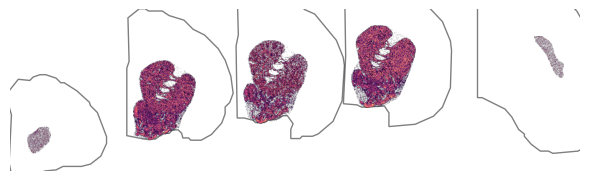

In [4]:
# plot marmoset DRD1 expression and stagger sections

figA_marm_DRD1, ax = plot_staggered_slab_sections(
    marm_slab_tables, 
    marm_hemisphere_outlines,
    gene_names=['DRD1'],
    offset_x=1,               # Horizontal stagger amount
    offset_y=0.1,                # Vertical stagger amount
    figsize=(6, 2),              # Adjust figure size
    mask_size=10,
    cmap='magma',
    spacing_mode='per_slice',
    )

plt.show()
if save_figs:
    figA_marm_DRD1.savefig('/results/marm_DRD1.png', dpi=dpi, bbox_inches='tight', transparent=True)
    figA_marm_DRD1.savefig('/results/marm_DRD1.svg', bbox_inches='tight', transparent=True)

In [6]:
# load spot tables from cached data
mac_barcode_manifest = pd.read_csv('/data/mac_merscope_barcodes/BM1205_coverslips_clean_14.csv')
mac_hemisphere_outline_path = Path('/data/macaque_bg_spatial_hemisphere_outlines')
mac_planes = {'CX.42': [5], 'CX.43': [7, 9, 11], 'CX.45': [9]}
mac_slab_tables_list = []
mac_hemisphere_outlines = []

for slab, sets in mac_planes.items():
    cx = mac_barcode_manifest[mac_barcode_manifest['slab']==slab]
    slab_name = slab.replace('.', '')

    for set_n in sets:
        cx_set = cx[cx['set']==set_n]
        slab_file = Path(f'/scratch/macaque_{slab_name}_Set{set_n}.npz')
        print(f'loading {slab_file}...')
        slab_spot_table = SpotTable.load_npz(slab_file)
        mac_slab_tables_list.append(slab_spot_table)

        hem_outline_coords = get_annotation_coords(slab_name, mac_hemisphere_outline_path)
        hem_outline_coords = np.array(hem_outline_coords)
        hem_outline_coords[:, 1] = -hem_outline_coords[:, 1]
        mac_hemisphere_outlines.append(hem_outline_coords) 

loading /scratch/macaque_CX42_Set5.npz...


loading /scratch/macaque_CX43_Set7.npz...
loading /scratch/macaque_CX43_Set9.npz...
loading /scratch/macaque_CX43_Set11.npz...
loading /scratch/macaque_CX45_Set9.npz...


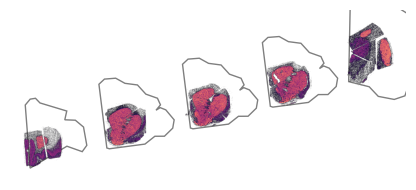

In [7]:
# Plot macaque DRD1 expression in staggered planes

figA_mac_DRD1, ax = plot_staggered_slab_sections(
    mac_slab_tables_list, 
    mac_hemisphere_outlines,
    gene_names=['DRD1'],
    offset_x=1,               # Horizontal stagger amount
    offset_y=0.2,                # Vertical stagger amount
    figsize=(6,2),              # Adjust figure size
    mask_size=0 ,           # continous pixels with signal   
    cmap='magma',
    spacing_mode='global',
    global_percentile=100,
    )

plt.show()
if save_figs:
    figA_mac_DRD1.savefig('/results/mac_DRD1.png', dpi=dpi, bbox_inches='tight', transparent=True)
    figA_mac_DRD1.savefig('/results/mac_DRD1.svg', bbox_inches='tight', transparent=True)

In [11]:
# load spot tables from cached data
human_barcode_manifest = pd.read_csv('/data/human_barcodes/human_barcodes_11.csv')
human_hemisphere_outline_path = Path('/data/human_bg_spatial_hemisphere_outlines')
human_planes = {'CX.13': [5], 'CX.17': [3, 5, 7], 'CX.19': [7]}
human_slab_tables_list = []
human_hemisphere_outlines = []

for slab, sets in human_planes.items():
    cx = human_barcode_manifest[human_barcode_manifest['slab']==slab]
    
    for set_n in sets:
        cx_set = cx[cx['set']==set_n]
        slab_file = Path(f'/scratch/human_{slab}_Set{set_n}.npz')
        slab_spot_table = SpotTable.load_npz(slab_file)
        human_slab_tables_list.append(slab_spot_table)
        
        hem_outline_coords = get_annotation_coords(slab_name, human_hemisphere_outline_path)
        hem_outline_coords = np.array(hem_outline_coords)
        hem_outline_coords[:, 1] = -hem_outline_coords[:, 1]
        human_hemisphere_outlines.append(hem_outline_coords)

loading /scratch/human_CX.13_Set5.npz...
loading /scratch/human_CX.17_Set3.npz...
loading /scratch/human_CX.17_Set5.npz...
loading /scratch/human_CX.17_Set7.npz...
loading /scratch/human_CX.19_Set7.npz...


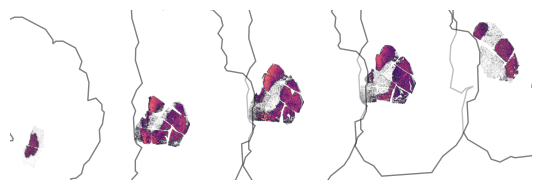

In [12]:
# Plot human DRD1 expresssion in staggered slabs
figA_human_DRD1, ax = plot_staggered_slab_sections(
    human_slab_tables_list, 
    human_hemisphere_outlines,
    gene_names=['DRD1'],
    offset_x=1,               # Horizontal stagger amount
    offset_y=0.1,                # Vertical stagger amount
    figsize=(6,2),              # Adjust figure size
    mask_size=0,            # continous pixels with signal   
    cmap='magma',
    spacing_mode='global',
    global_percentile=5
    )

plt.show()
if save_figs:
    figA_human_DRD1.savefig('/results/human_DRD1.png', dpi=dpi, bbox_inches='tight', transparent=True)
    figA_human_DRD1.savefig('/results/human_DRD1.svg', bbox_inches='tight', transparent=True)

Load QC'ed spatial cells from each species and plot each slab, with hemisphere outline, where cells are colored by Group and regions sampled in each slab are annotated

In [4]:
# Load and plot marmoset data
marm_file = '/data/cirro_files_hmba_marmoset_CJ23.56.004_BG_revisions_20260811/marmoset-Xenium-CJ23.56.004-Tank_BG_release_format_20260811_all_cells.h5ad'
marm_obs = load_anndata_obs(marm_file, species='marmoset', qc=True)

Aligning rotated coordinates across sections for marmoset...


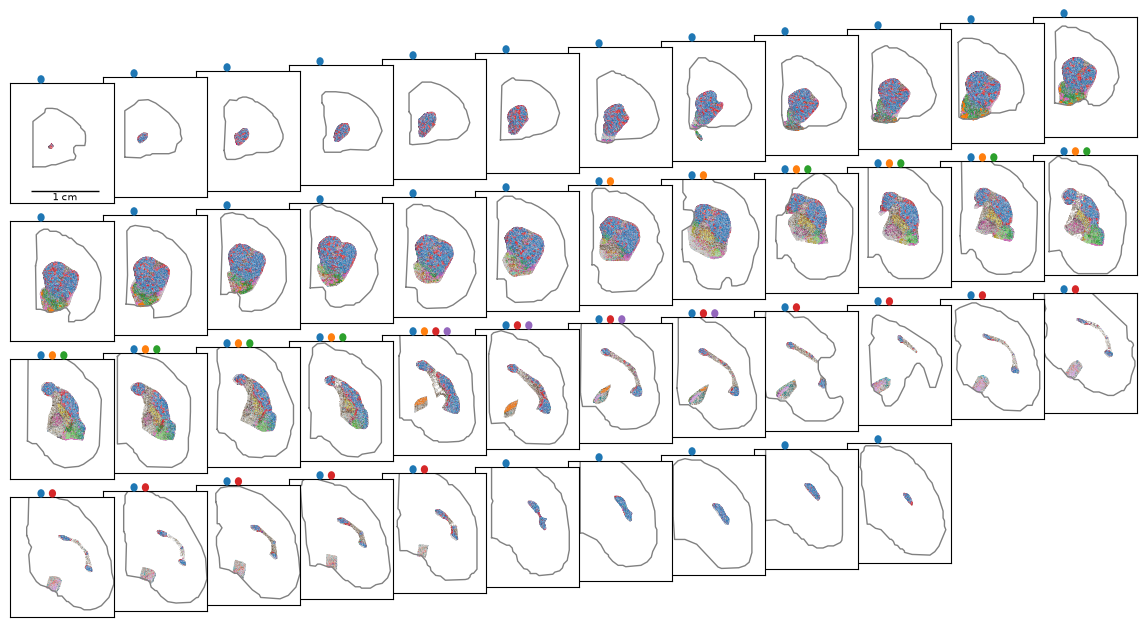

In [5]:
bg_kwargs = {'legend': False, 'hue': 'Group', 'palette': group_color_dict, 'rasterized': True, 'edgecolor': None, 's':0.1, 'alpha':0.3}
fg_kwargs = {'legend': False, 'hue': 'Group', 'palette': group_color_dict, 'rasterized': True, 'edgecolor': None, 's':0.2, 'alpha':0.8}
marm_hemisphere_outlines = '/data/marmoset_hmba_bg_spatial_hemisphere_outlines'
scalebar_params = {'size': 10000, 'label': '1 cm', 'offset': (0.2, 0.1)}
figA_marm_montage = plot_section_montage(marm_obs, 'x_rotated', 'y_rotated', fg_kwargs, bg_kwargs, ncols=12, h_overlap=0.015, v_overlap=-0.03, 
                                            flip_y=False, zoom_radius=3000, hemisphere_outlines=marm_hemisphere_outlines, scalebar=scalebar_params)
if save_figs:
    figA_marm_montage.savefig('/results/marm_montage.png', dpi=dpi, bbox_inches='tight', transparent=True)
    figA_marm_montage.savefig('/results/marm_montage.svg', bbox_inches='tight', transparent=True)

In [6]:
# Load and plot macaque data

mac_file = '/data/cirro_files_hmba_macaque_20260811/hmba_release_format_macaque_cirro_h5ad_20260716_newnames_20260811.h5ad'
mac_obs = load_anndata_obs(mac_file, species='macaque', qc=True)

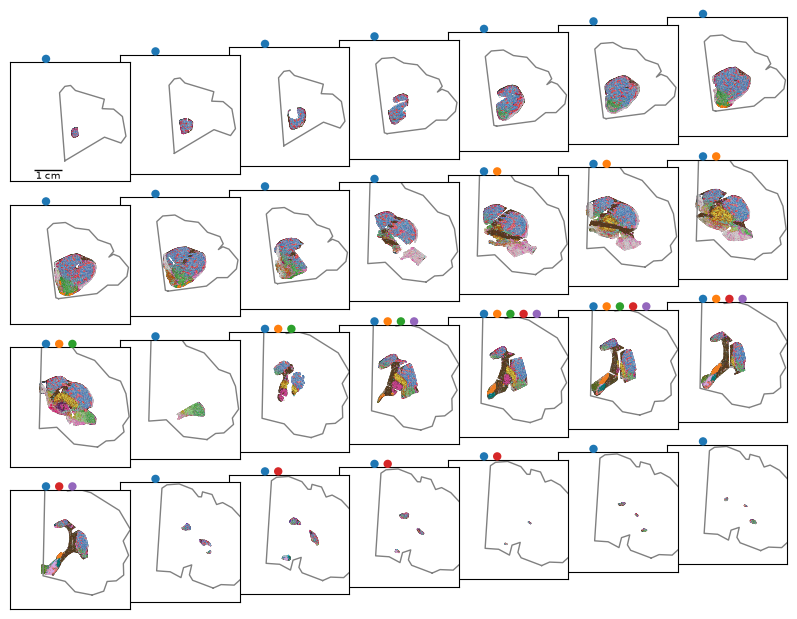

In [7]:
bg_kwargs = {'legend': False, 'hue': 'Group', 'palette': group_color_dict, 'rasterized': True, 'edgecolor': None, 's':0.1, 'alpha':0.3}
fg_kwargs = {'legend': False, 'hue': 'Group', 'palette': group_color_dict, 'rasterized': True, 'edgecolor': None, 's':0.2, 'alpha':0.8}
hem_outlines_path = '/data/macaque_bg_spatial_hemisphere_outlines'
scalebar_params = {'size': 500, 'label': '1 cm', 'offset': (0.2, 0.1)}
figA_mac_montage = plot_section_montage(mac_obs, 'x_slab', 'y_slab', fg_kwargs, bg_kwargs, ncols=7, v_overlap=-0.03, zoom_radius=500, 
                    hemisphere_outlines=hem_outlines_path, scalebar=scalebar_params)
if save_figs:
    figA_mac_montage.savefig('/results/mac_montage.png', dpi=dpi, bbox_inches='tight', transparent=True)
    figA_mac_montage.savefig('/results/mac_montage.svg', bbox_inches='tight', transparent=True)

In [8]:
# Load and plot human data
human_file = '/data/cirro_files_hmba_human_20260811/hmba_release_format_human_cirro_h5ad_20260716_newnames_20260811.h5ad'
human_obs = load_anndata_obs(human_file, qc=True, species='human')
human_obs['z_order'] = human_obs['z_order'] - 2
human_obs.loc[human_obs['z_order'] == -2, 'z_order'] = 17
human_obs.loc[human_obs['z_order'] == -1, 'z_order'] = 18

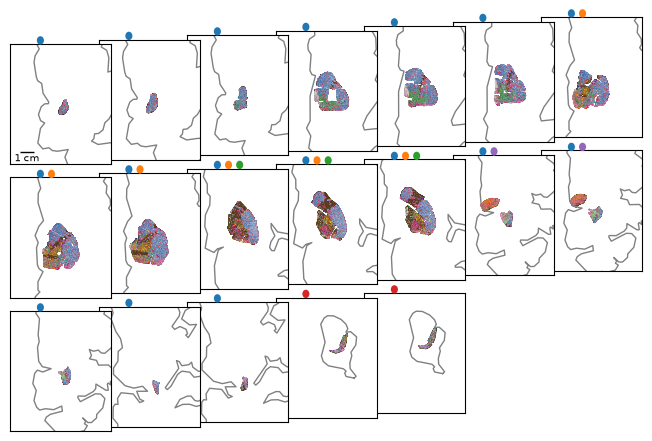

In [9]:
bg_kwargs = {'legend': False, 'hue': 'Group', 'palette': group_color_dict, 'rasterized': True, 'edgecolor': None, 's':0.1, 'alpha':0.3}
fg_kwargs = {'legend': False, 'hue': 'Group', 'palette': group_color_dict, 'rasterized': True, 'edgecolor': None, 's':0.2, 'alpha':0.8}
hem_outline_path = '/data/human_bg_spatial_hemisphere_outlines'
scalebar_params = {'size': 500, 'label': '1 cm', 'offset': (0.1, 0.1)}
figA_human_montage = plot_section_montage(human_obs, 'x_slab', 'y_slab', fg_kwargs, bg_kwargs, ncols=7, h_overlap=0.03, v_overlap=-0.03, zoom_radius=1000, 
                        hemisphere_outlines=hem_outline_path, scalebar=scalebar_params)
if save_figs:
    figA_human_montage.savefig('/results/human_montage.png', dpi=dpi, bbox_inches='tight', transparent=True)
    figA_human_montage.savefig('/results/human_montage.svg',bbox_inches='tight', transparent=True)

Figure 1E
Compare Group level spatial cell type proportions across species and compared to snRNAseq reference

In [11]:
## load snRNAseq data

rnaseq_counts = pd.read_csv('/data/HMBA_BG_rnaseq_cell_counts/group_counts_per_species.csv')
rnaseq_counts.rename(columns={'n_cells_group_per_organism': 'count'}, inplace=True)
anno_file = '/data/HMBA-BG-annotation-lookup-20260528/annotation_lookup_table_final.csv'
rnaseq_counts = bg_rename(rnaseq_counts, anno_file, levels=['Group'])
rnaseq_counts.head()

,organism,count,Group
0,Human,188,AMY-SLEA-BNST D1 GABA
1,Macaque,479,AMY-SLEA-BNST D1 GABA
2,Marmoset,0,AMY-SLEA-BNST D1 GABA
3,Human,2199,AMY-SLEA-BNST GABA
4,Macaque,3295,AMY-SLEA-BNST GABA


In [12]:
# Categorize Groups into Neuron and Non-Neuron
marm_group_mapping = marm_obs[['Group', 'Class', 'Neighborhood', 'Subclass']].drop_duplicates()
mac_group_mapping = mac_obs[['Group', 'Class', 'Neighborhood', 'Subclass']].drop_duplicates()
human_group_mapping = human_obs[['Group', 'Class', 'Neighborhood', 'Subclass']].drop_duplicates()

group_mapping = pd.merge(marm_group_mapping, mac_group_mapping, on='Group', how='inner', suffixes=('', '_remove'))
group_mapping = pd.merge(group_mapping, human_group_mapping, on='Group', how='inner', suffixes=('', '_remove'))
remove_cols = [c for c in group_mapping if c.endswith('_remove')]
group_mapping.drop(columns=remove_cols, inplace=True)

neurons = group_mapping[group_mapping['Neighborhood']!= 'Nonneuron']['Group'].unique().tolist()
neurons.remove('Adjacent')
non_neurons = group_mapping[group_mapping['Neighborhood']== 'Nonneuron']['Group'].unique().tolist()

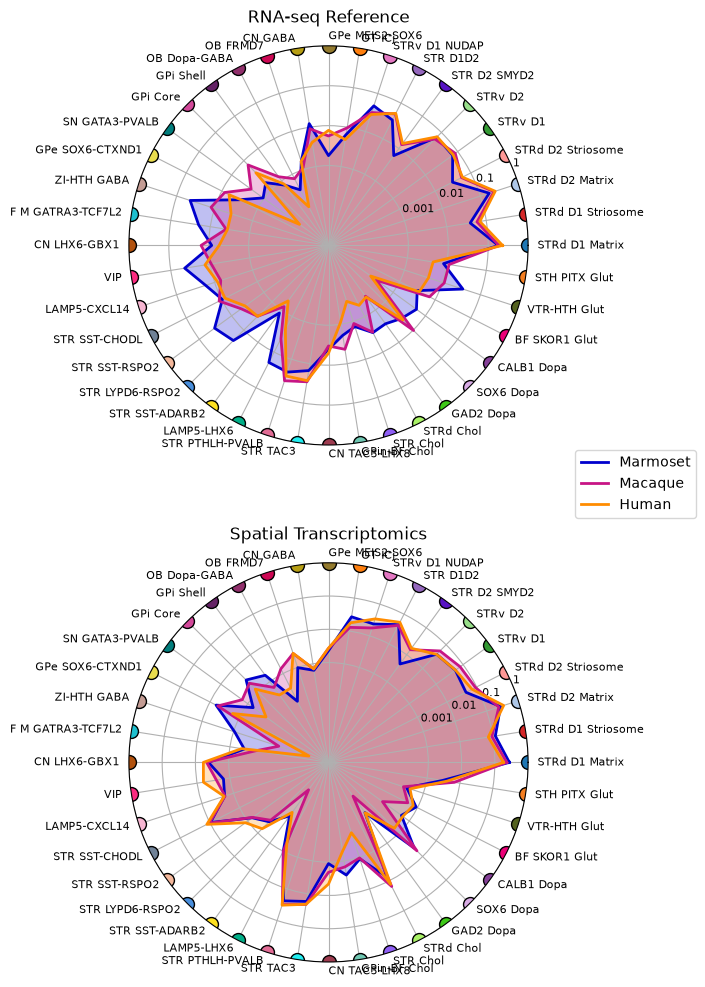

In [14]:
# Calculate log proptions of neurons for each modality and each species

display_order = [g for g in GROUP_DISPLAY_ORDER if g in neurons]

neuron_prop_fig, ax = plt.subplots(2, 1, figsize=(8, 10), subplot_kw=dict(polar=True))

rnaseq_prop = []
for species in ['Marmoset', 'Macaque', 'Human']:
    obs = rnaseq_counts[rnaseq_counts['organism']==species]
    neuron_prop = calculate_group_proportions(obs, neurons)
    rnaseq_prop.append(neuron_prop['log_proportion'].rename(species, inplace=True))

rnaseq_neuron = pd.concat(rnaseq_prop, axis=1)
rnaseq_neuron = rnaseq_neuron.loc[display_order]
rnaseq_neuron.rename(index=GROUP_SHORT_NAMES, inplace=True)
colors = {GROUP_SHORT_NAMES[c]: group_color_dict[c] for c in display_order}

plot_radial_proportions(rnaseq_neuron, ax=ax[0], legend=False, pad=0.05, fontsize=8, label_colors=colors)
ax[0].set_title('RNA-seq Reference', fontsize=12)


spatial_prop = []
for species, obs in {'Marmoset': marm_obs, 'Macaque': mac_obs, 'Human': human_obs}.items():
    neuron_prop = calculate_group_proportions(obs, neurons, region=['STR', 'GP', 'GPe', 'GPi', 'SN', 'STH'])
    spatial_prop.append(neuron_prop['log_proportion'].rename(species, inplace=True))

spatial_neuron = pd.concat(spatial_prop, axis=1)
spatial_neuron = spatial_neuron.loc[display_order]
spatial_neuron.rename(index=GROUP_SHORT_NAMES, inplace=True)
colors = {GROUP_SHORT_NAMES[c]: group_color_dict[c] for c in display_order}

plot_radial_proportions(spatial_neuron, ax[1], bbox_to_anchor=(1.1, 1.3), pad=0.05, fontsize=8, label_colors=colors)
ax[1].set_title('Spatial Transcriptomics', fontsize=12)

plt.tight_layout(h_pad=0.25)
plt.show()

if save_figs:
    neuron_prop_fig.savefig('/results/neuron_prop_radial.png', dpi=dpi, bbox_inches='tight', transparent=True)
    neuron_prop_fig.savefig('/results/neuron_prop_radial.svg', bbox_inches='tight', transparent=True)

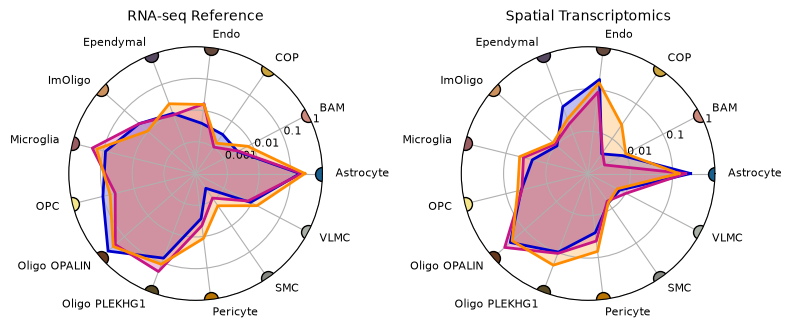

In [15]:
# Calculate log proptions of non-neurons for each modality and each species (Panels in Supplemental Figure 3A)
non_neurons = group_mapping[group_mapping['Neighborhood']== 'Nonneuron']['Group'].unique().tolist()

non_neuron_prop_fig, ax = plt.subplots(1, 2, figsize=(8, 6), subplot_kw=dict(polar=True))

rnaseq_prop = []
for species in ['Marmoset', 'Macaque', 'Human']:
    obs = rnaseq_counts[rnaseq_counts['organism']==species]
    nn_prop = calculate_group_proportions(obs, non_neurons)
    rnaseq_prop.append(nn_prop['log_proportion'].rename(species, inplace=True))

rnaseq_nn = pd.concat(rnaseq_prop, axis=1)

plot_radial_proportions(rnaseq_nn, ax=ax[0], legend=False, pad=0.05, fontsize=8, label_colors=group_color_dict)
ax[0].set_title('RNA-seq Reference', fontsize=10)

spatial_prop = []
for species, obs in {'Marmoset': marm_obs, 'Macaque': mac_obs, 'Human': human_obs}.items():
    nn_prop = calculate_group_proportions(obs, non_neurons)
    spatial_prop.append(nn_prop['log_proportion'].rename(species, inplace=True))

spatial_nn = pd.concat(spatial_prop, axis=1)

plot_radial_proportions(spatial_nn, ax[1], legend=False, pad=0.05, fontsize=8, label_colors=group_color_dict)
ax[1].set_title('Spatial Transcriptomics', fontsize=10)

plt.tight_layout()
plt.show()

if save_figs:
    non_neuron_prop_fig.savefig('/results/nn_prop_radial.png', dpi=dpi, bbox_inches='tight', transparent=True)
    non_neuron_prop_fig.savefig('/results/nn_prop_radial.svg', bbox_inches='tight', transparent=True)

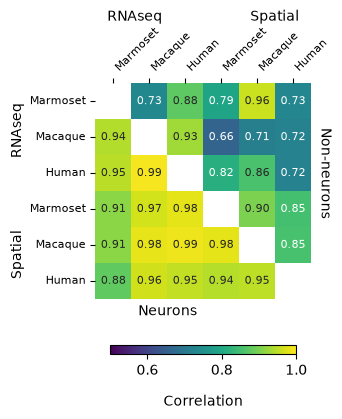

In [16]:
# Calculate and plot correlation heatmap between modalities and species
neuron_props = rnaseq_neuron.merge(spatial_neuron, left_index=True, right_index=True, how='inner', suffixes=('_RNAseq', '_Spatial'))
neuron_props = 10**neuron_props
neuron_props_corr = neuron_props.corr(method='pearson')

nn_props = rnaseq_nn.merge(spatial_nn, left_index=True, right_index=True, how='inner', suffixes=('_RNAseq', '_Spatial'))
nn_props = 10**nn_props
nn_props_corr = nn_props.corr(method='pearson')

lower_array = neuron_props_corr.to_numpy()
upper_array = nn_props_corr.to_numpy()
combined = np.full_like(lower_array, np.nan, dtype=float)
n = combined.shape[0]
upper = np.triu_indices(n, k=1)
combined[upper] = upper_array[upper]
lower = np.tril_indices(n, k=-1)
combined[lower] = lower_array[lower]
mask = np.isnan(combined)

combined_df = pd.DataFrame(combined, index=neuron_props_corr.index, columns=neuron_props_corr.columns)

corr_fig, ax = plt.subplots(figsize=(4,4))

heatmap = sns.heatmap(combined_df, mask=mask, annot=True, fmt='0.2f', annot_kws={"size": 8}, cmap='viridis', vmin=0.5, vmax=1, square=True, cbar=False)

labels = ['Marmoset', 'Macaque', 'Human', 'Marmoset', 'Macaque', 'Human']
ax.set_xticklabels(labels, fontsize=8, rotation=45, ha='left')
ax.set_xlabel('RNAseq                      Spatial')
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')
ax.set_yticklabels(labels, fontsize=8)
ax.set_ylabel('Spatial                  RNAseq')
corr_fig.text(0.35, 0.3, 'Neurons')
corr_fig.text(0.8, 0.55, 'Non-neurons', rotation=270)

cbar = corr_fig.colorbar(heatmap.collections[0], ax=ax, location='bottom', orientation='horizontal', shrink=0.6, pad=0.15)
cbar.set_label('Correlation', labelpad=12)

plt.show()

if save_figs:
    corr_fig.savefig('/results/prop_corr.png', dpi=dpi, bbox_inches='tight', transparent=True)
    corr_fig.savefig('/results/prop_corr.svg', bbox_inches='tight', transparent=True)

Figure 1F
Calculate cell counts at the Group level and their proportion in each region for each species

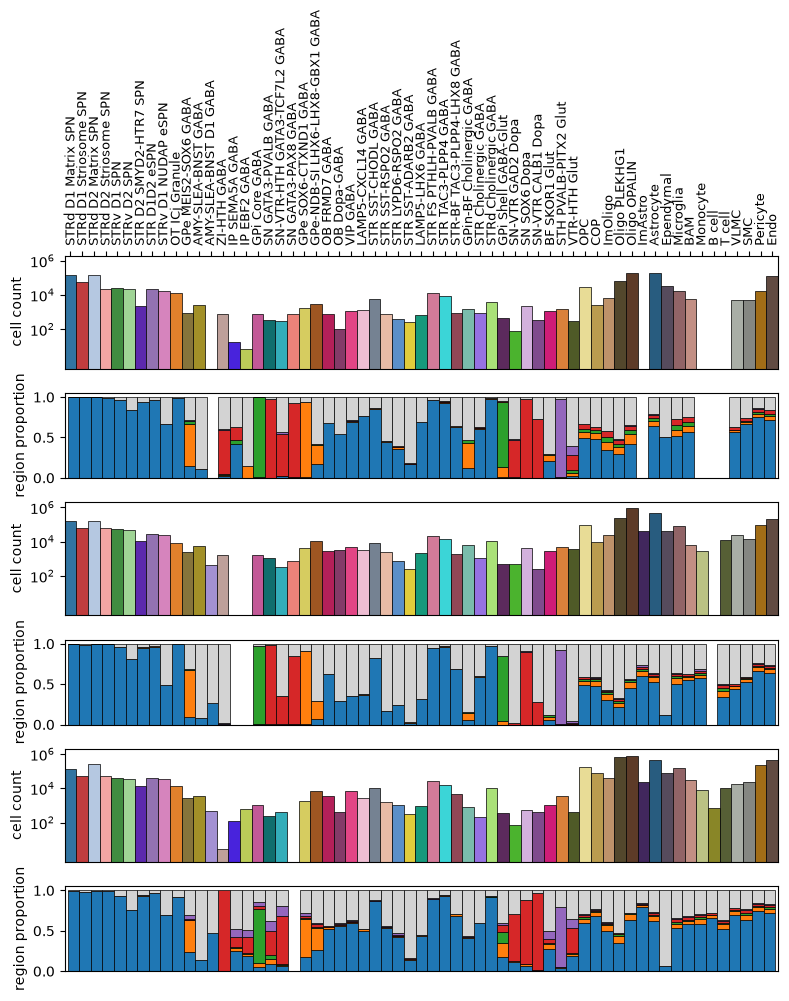

In [17]:
cell_counts, ax = plt.subplots(6, 1, figsize=(8, 10), gridspec_kw={'height_ratios': [2, 1.5, 2, 1.5, 2, 1.5]})

anno_cols = ['STR', 'GPe', 'GPi', 'SN', 'STH', 'basal_ganglia_and_adjacent']
tab10 = plt.get_cmap("tab10")
region_colors = [tab10(i) for i in range(5)]
region_colors.append("lightgrey")

i = 0
for species_obs in [marm_obs, mac_obs, human_obs]:
    species_groups = species_obs['Group'].cat.categories
    not_in_species = list(set(GROUP_DENDROGRAM_ORDER) - set(species_groups))
    
    group_counts = species_obs.groupby('Group').size().reset_index(name='count')

    sns.barplot(data=group_counts, x='Group', y='count', ax=ax[i], width=1, order=GROUP_DENDROGRAM_ORDER, palette=group_color_dict, edgecolor='black', linewidth=0.5, legend=False)
    ax[i].set_yscale('log')
    ax[i].set_ylabel('cell count')
    ax[i].set_ylim(0.5, 0.2e7)
    ax[i].set_yticks([1e2, 1e4, 1e6])
    # ax[i].invert_yaxis()
    ax[i].set_xlabel('')
    if i == 0: 
        ax[i].tick_params(axis='x', top=True, labeltop=True, bottom=False, labelbottom=False) 
        ax[i].set_xticklabels(GROUP_DENDROGRAM_ORDER, fontsize=9, rotation=90)
    else: 
        ax[i].set_xticklabels('') 
        ax[i].tick_params(axis='x', length=0) 
        
    group_anno = cell_count_per_structure(species_obs, anno_cols)
    group_anno = pd.concat([group_anno, pd.DataFrame(index=not_in_species)])
    group_anno_norm = group_anno.loc[GROUP_DENDROGRAM_ORDER, anno_cols].div(
        group_anno.loc[GROUP_DENDROGRAM_ORDER, anno_cols].sum(axis=1), axis=0
    )

    group_anno_norm.loc[GROUP_DENDROGRAM_ORDER].plot(kind='bar', stacked=True, ax=ax[i+1], width=1, edgecolor='black', color=region_colors, linewidth=0.5, legend=False) 
    ax[i+1].set_ylabel('region proportion')
    ax[i+1].set_yticks([0, 0.5, 1])  
    ax[i+1].set_xticklabels('')
    ax[i+1].tick_params(axis='x', length=0)

    i += 2  

plt.margins(x=0)
plt.tight_layout()
plt.show()

if save_figs:
    cell_counts.savefig('/results/cell_counts.png', dpi=dpi, bbox_inches='tight', transparent=True)
    cell_counts.savefig('/results/cell_counts.svg', bbox_inches='tight', transparent=True)